In [76]:
import os
os.environ["PYARROW_IGNORE_TIMEZONE"] = "1"

import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, sum

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from fairlearn.metrics import (
    MetricFrame, selection_rate,
    demographic_parity_difference, equalized_odds_difference
)

import shap

warnings.filterwarnings("ignore")


In [77]:
# Create a SparkSession
spark_context= SparkSession.builder \
    .appName("RedliningAnalysis") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

In [78]:
# from google.colab import drive
# drive.mount('/content/drive')

In [79]:
file_path = "clean_hmda_random_sample_2020_2023.csv"
truist_census = spark_context.read.csv(file_path, inferSchema=True, header=True)

In [80]:
selected_df = truist_census.toPandas()

### EDA, let's see how many nulls

In [81]:
selected_df.shape

(974751, 29)

In [82]:
for col in selected_df.columns:
    print(col + " " + str(selected_df[col].dtype))

loan_amount float64
loan_to_value_ratio float64
loan_type int32
loan_purpose int32
debt_to_income_ratio float64
income float64
loan_term float64
interest_rate float64
property_value float64
applicant_credit_score_type float64
derived_loan_product_type object
occupancy_type int32
state_code object
county_code float64
tract_to_msa_income_percentage float64
tract_owner_occupied_units int32
submission_of_application float64
preapproval int32
business_or_commercial_purpose float64
activity_year int32
rate_spread float64
tract_minority_population_percent float64
derived_race object
derived_ethnicity object
derived_sex object
applicant_age object
lei object
census_tract float64
action_taken int32


In [83]:
# Check the null values
null_counts = selected_df.isnull().sum()
null_counts.sort_values(ascending=False).head(50)

census_tract                         10275
county_code                           7469
loan_amount                              0
tract_owner_occupied_units               0
lei                                      0
applicant_age                            0
derived_sex                              0
derived_ethnicity                        0
derived_race                             0
tract_minority_population_percent        0
rate_spread                              0
activity_year                            0
business_or_commercial_purpose           0
preapproval                              0
submission_of_application                0
tract_to_msa_income_percentage           0
loan_to_value_ratio                      0
state_code                               0
occupancy_type                           0
derived_loan_product_type                0
applicant_credit_score_type              0
property_value                           0
interest_rate                            0
loan_term  

📋 Action Taken (Counts & %):
               Count  Percent
action_taken                 
1             551808    56.61
2              22858     2.35
3             124538    12.78
4             125540    12.88
5              46359     4.76
6             101231    10.39
7                773     0.08
8               1644     0.17

📋 Activity Year (Counts):
activity_year
2020    302341
2021    224675
2022    187645
2023    260090
Name: count, dtype: int64


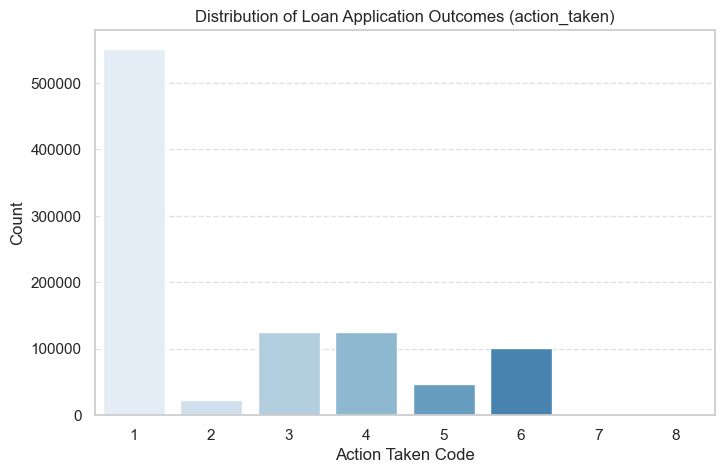

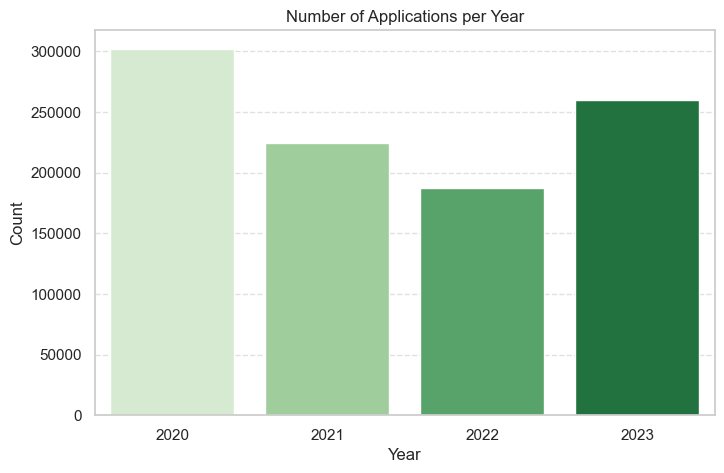

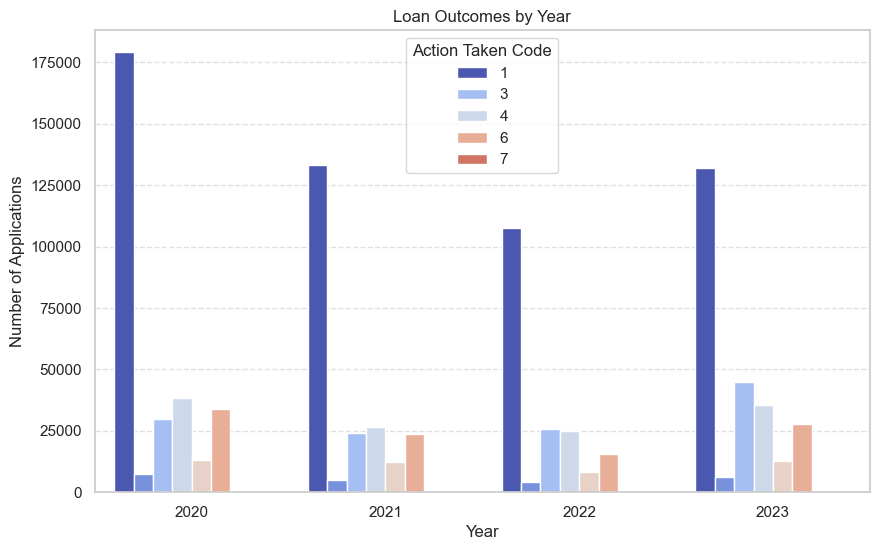

In [84]:
# --- Frequency table ---
print("📋 Action Taken (Counts & %):")
action_counts = selected_df['action_taken'].value_counts(dropna=False).sort_index()
action_perc = selected_df['action_taken'].value_counts(normalize=True, dropna=False).sort_index() * 100
action_table = pd.DataFrame({'Count': action_counts, 'Percent': action_perc.round(2)})
print(action_table)

print("\n📋 Activity Year (Counts):")
print(selected_df['activity_year'].value_counts().sort_index())

# --- Visualization 1: Action Taken Histogram ---
plt.figure(figsize=(8,5))
sns.countplot(data=selected_df, x='action_taken', palette='Blues')
plt.title('Distribution of Loan Application Outcomes (action_taken)')
plt.xlabel('Action Taken Code')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# --- Visualization 2: Applications per Year ---
plt.figure(figsize=(8,5))
sns.countplot(data=selected_df, x='activity_year', palette='Greens')
plt.title('Number of Applications per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# --- Optional: Cross-tab Year vs Action Taken ---
plt.figure(figsize=(10,6))
sns.countplot(data=selected_df, x='activity_year', hue='action_taken', palette='coolwarm')
plt.title('Loan Outcomes by Year')
plt.xlabel('Year')
plt.ylabel('Number of Applications')
plt.legend(title='Action Taken Code')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

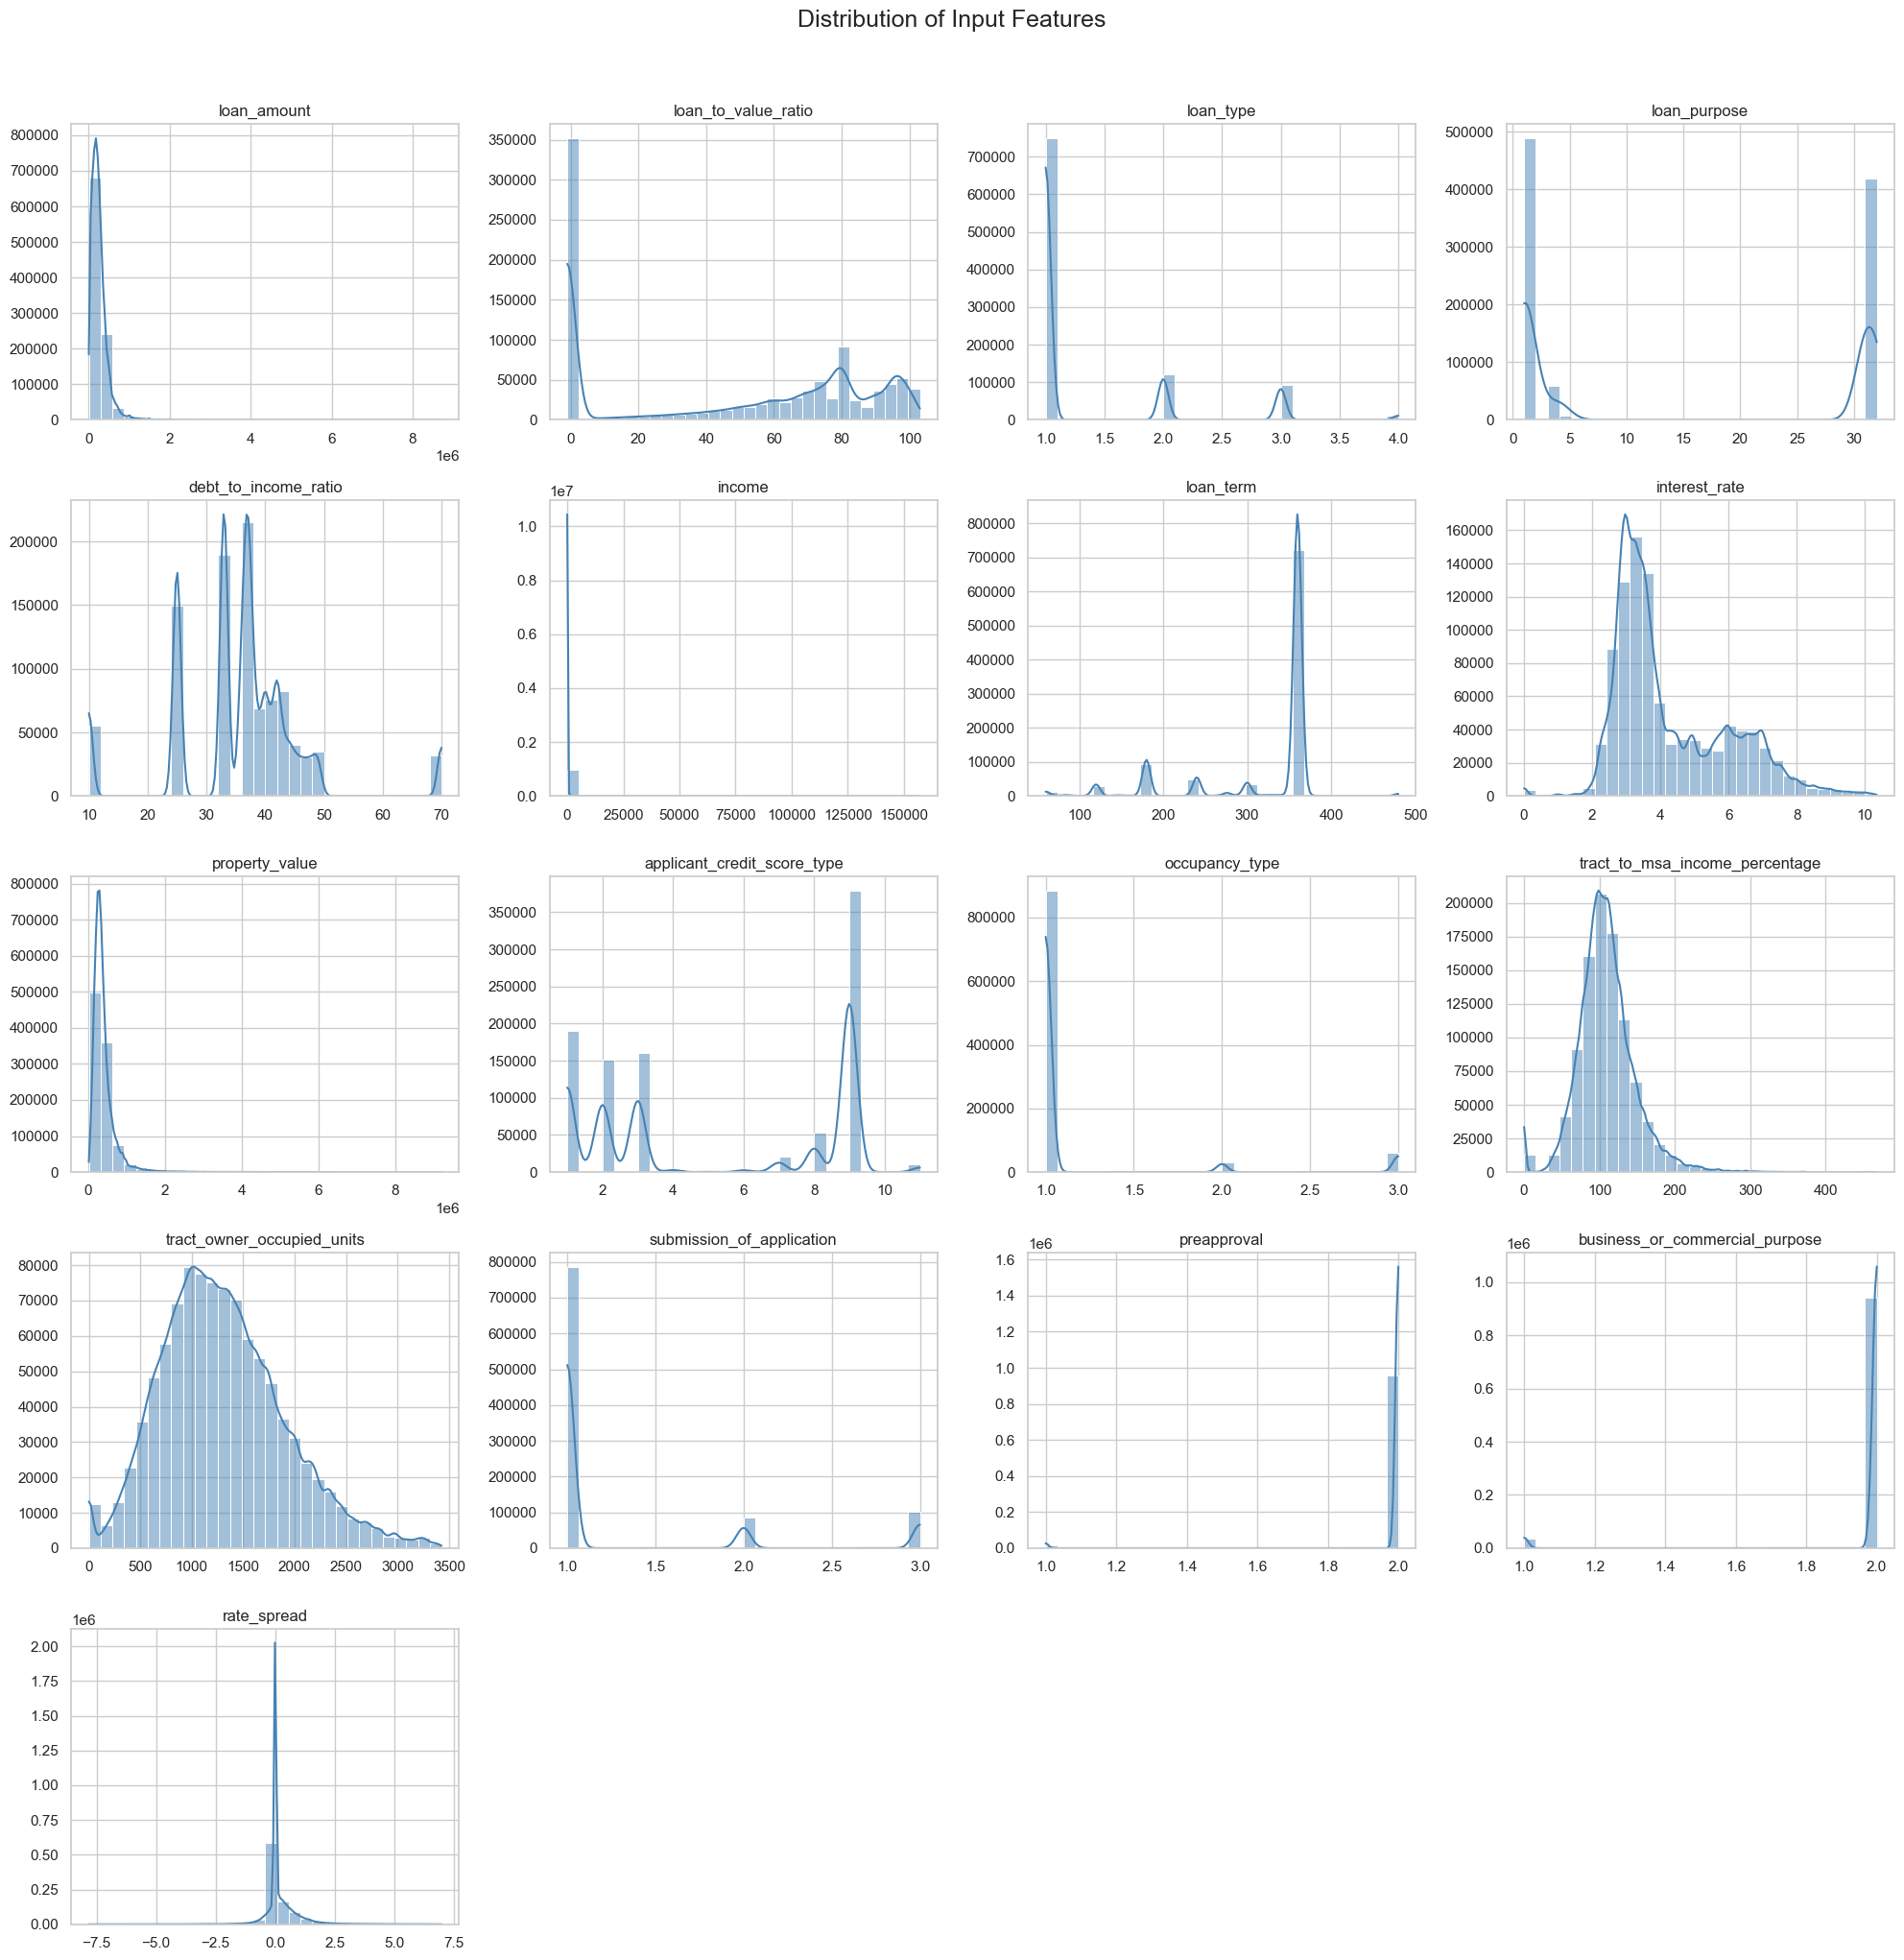

In [85]:
# List of input features
features = [
    'loan_amount', 'loan_to_value_ratio', 'loan_type', 'loan_purpose',
    'debt_to_income_ratio', 'income', 'loan_term', 'interest_rate',
    'property_value', 'applicant_credit_score_type', 'occupancy_type',
    'tract_to_msa_income_percentage', 'tract_owner_occupied_units',
    'submission_of_application', 'preapproval', 'business_or_commercial_purpose',
    'rate_spread'
]

# Determine grid size automatically (approx square layout)
n_features = len(features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

plt.figure(figsize=(n_cols * 5, n_rows * 4))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, i)
    if selected_df[col].dtype in ['float64', 'int64', 'int32']:
        # Numeric: use histogram
        sns.histplot(selected_df[col].dropna(), kde=True, bins=30, color='steelblue')
    else:
        # Categorical: use countplot
        sns.countplot(data=selected_df, x=col, palette='Set2')
        plt.xticks(rotation=45)
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('')

plt.suptitle('Distribution of Input Features', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


In [86]:
# Define mapping logic
def map_action_taken(x):
    if x in [1, 2]:
        return 1   # Approved
    elif x in [3, 4, 5]:
        return 0   # Denied
    else:
        return np.nan  # Exclude from modeling

# Apply mapping
selected_df['loan_approved'] = selected_df['action_taken'].apply(map_action_taken)

# Filter only rows where we have a valid binary label
selected_df = selected_df[selected_df['loan_approved'].notna()]

# Show distribution
print(selected_df['loan_approved'].value_counts(normalize=True) * 100)


loan_approved
1.0    65.969925
0.0    34.030075
Name: proportion, dtype: float64


In [87]:
# Define target columns
cols = ['derived_race', 'derived_ethnicity', 'derived_sex']

# Compute frequencies for each
for col in cols:
    print(f"\n=== Frequency Distribution: {col} ===")
    freq = (
        selected_df[col]
        .value_counts(dropna=False)  # include NaN if any
        .to_frame('count')
        .reset_index()
        .rename(columns={'index': col})
    )
    freq['percentage'] = (freq['count'] / len(selected_df) * 100).round(2)
    print(freq)


=== Frequency Distribution: derived_race ===
                                derived_race   count  percentage
0                                      White  597706       68.61
1                         Race Not Available  147158       16.89
2                  Black or African American   51789        5.95
3                                      Asian   41831        4.80
4                                      Joint   19507        2.24
5           American Indian or Alaska Native    6837        0.78
6  Native Hawaiian or Other Pacific Islander    3582        0.41
7                   2 or more minority races    2573        0.30
8                        Free Form Text Only     120        0.01

=== Frequency Distribution: derived_ethnicity ===
         derived_ethnicity   count  percentage
0   Not Hispanic or Latino  643812       73.91
1  Ethnicity Not Available  146774       16.85
2       Hispanic or Latino   61849        7.10
3                    Joint   18265        2.10
4      Free Form T

In [88]:
# Replace special missing categories with "Unknown"
selected_df['derived_race'] = selected_df['derived_race'].replace({
    "Race Not Available": "Unknown",
    "Free Form Text Only": "Unknown"
})

selected_df['derived_ethnicity'] = selected_df['derived_ethnicity'].replace({
    "Ethnicity Not Available": "Unknown",
    "Free Form Text Only": "Unknown"
})

selected_df['derived_sex'] = selected_df['derived_sex'].replace({
    "Sex Not Available": "Unknown"
})



🔹 Overall approval rate: To understand class balance (approved vs denied).


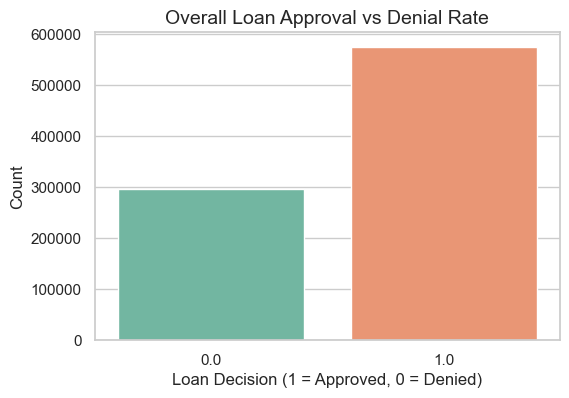


🔹 Detect potential racial bias in loan approvals.


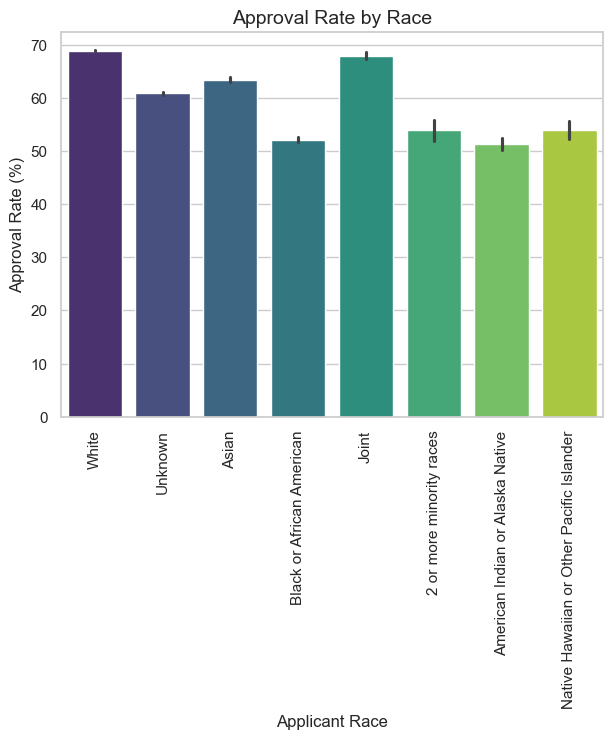


🔹 Examine fairness gaps across ethnicity and gender groups.


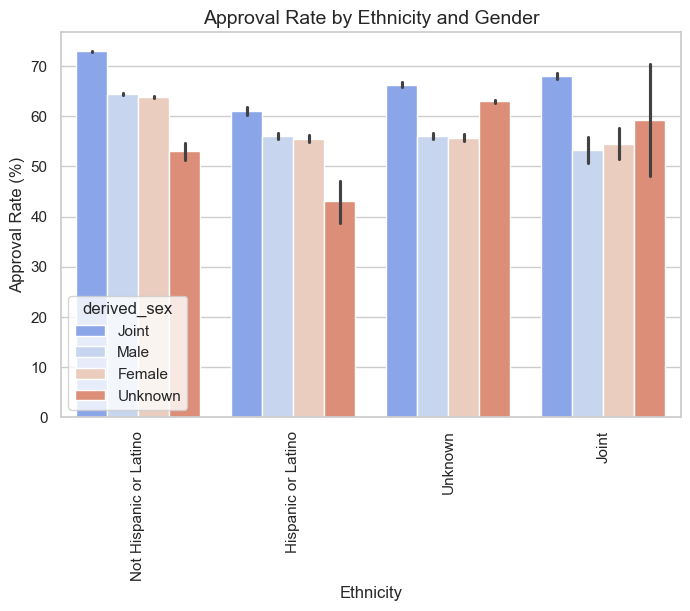


🔹 Check whether higher loan amounts face higher denial likelihood.


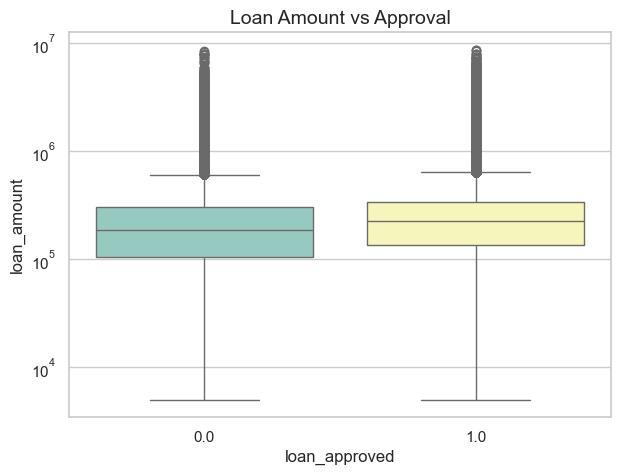


🔹 Analyze how Debt-to-Income (DTI) ratios affect approval probability.


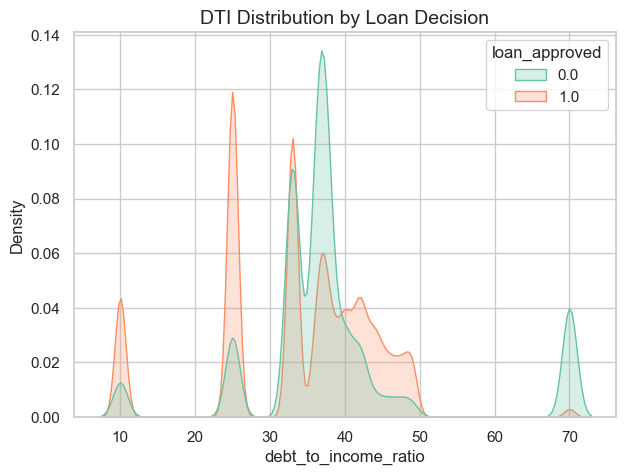


🔹 Identify if higher Loan-to-Value (LTV) ratios lead to more denials.


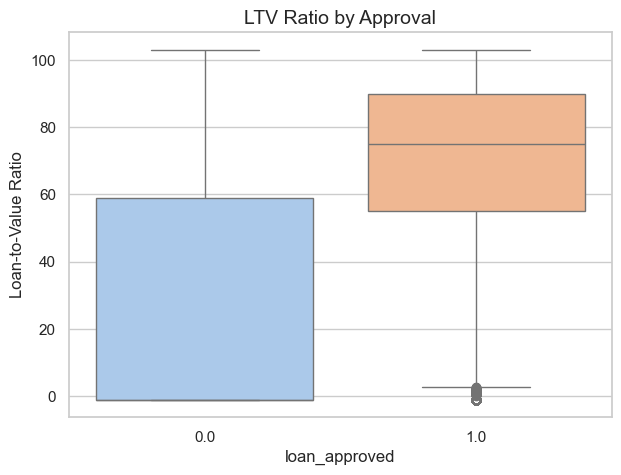


🔹 Compare approval disparities across different states.


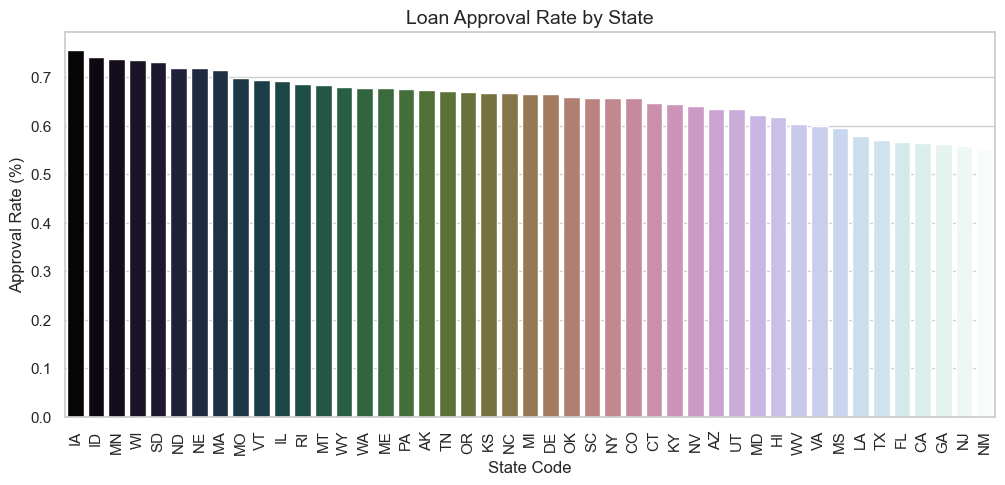


🔹 Examine if racial approval gaps persist across different income levels.


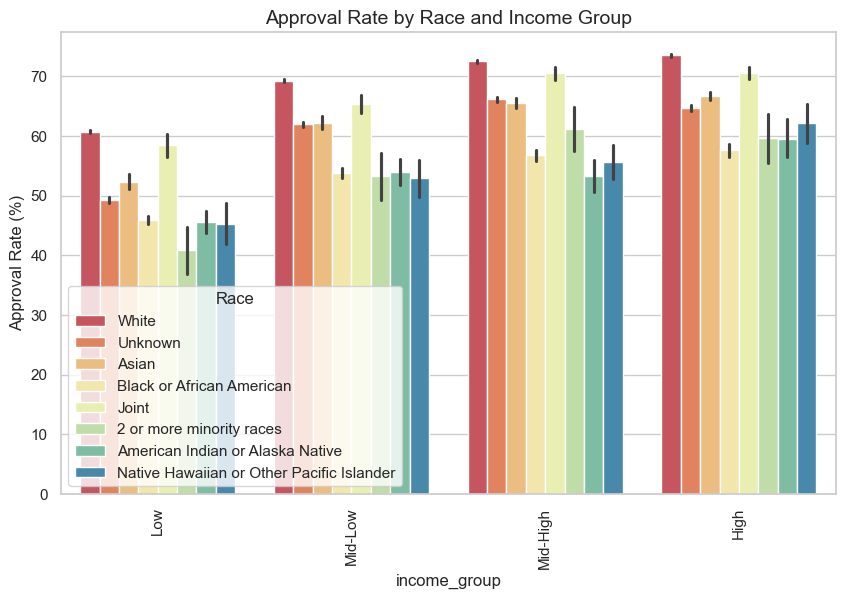


🔹 Track fairness and approval trends across years (detect regulatory improvements).


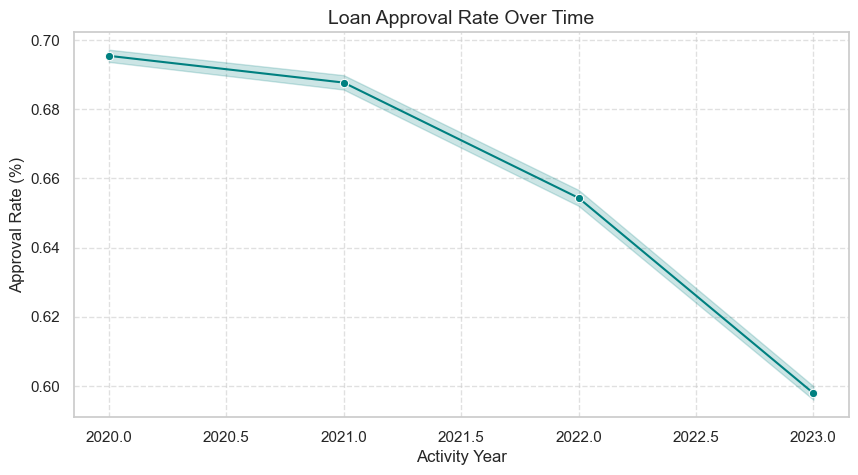


🔹 Identify numeric variables most related to loan approval outcomes.


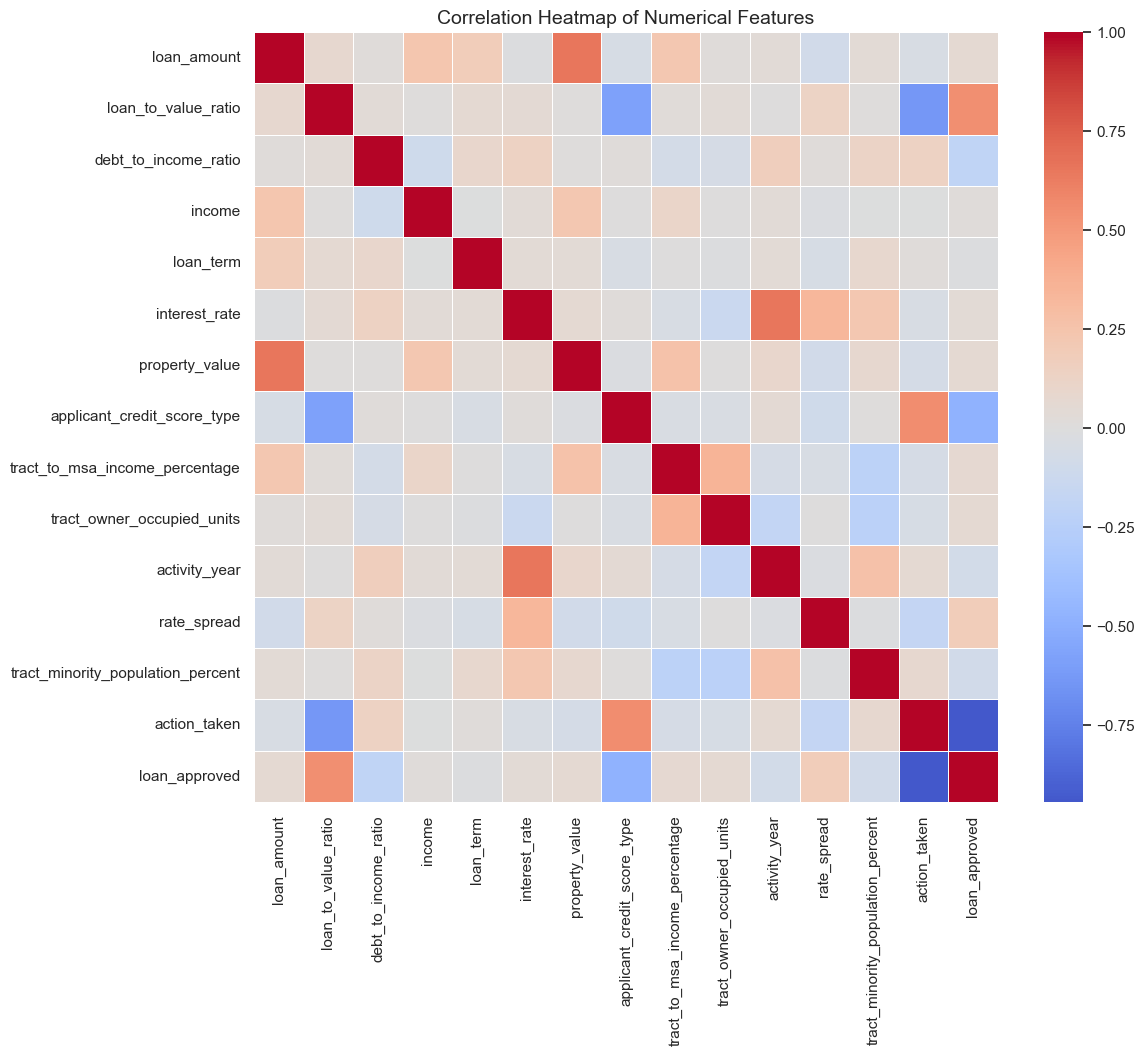

In [89]:
# -----------------------------
# STYLE SETTINGS
# -----------------------------
sns.set(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12


# =============================
# A. OVERALL APPROVAL PATTERNS
# =============================
print("\n🔹 Overall approval rate: To understand class balance (approved vs denied).")
plt.figure(figsize=(6,4))
sns.countplot(x='loan_approved', data=selected_df, palette='Set2')
plt.title("Overall Loan Approval vs Denial Rate")
plt.xlabel("Loan Decision (1 = Approved, 0 = Denied)")
plt.ylabel("Count")
plt.show()


# =============================
# B. DEMOGRAPHIC FAIRNESS ANALYSIS
# =============================
print("\n🔹 Detect potential racial bias in loan approvals.")
plt.figure(figsize=(7,5))
sns.barplot(x='derived_race', y='loan_approved', data=selected_df,
            estimator=lambda x: np.mean(x)*100, palette='viridis')
plt.title("Approval Rate by Race")
plt.ylabel("Approval Rate (%)")
plt.xlabel("Applicant Race")
plt.xticks(rotation=90)
plt.show()

print("\n🔹 Examine fairness gaps across ethnicity and gender groups.")
plt.figure(figsize=(8,5))
sns.barplot(x='derived_ethnicity', hue='derived_sex', y='loan_approved',
            data=selected_df, estimator=lambda x: np.mean(x)*100, palette='coolwarm')
plt.title("Approval Rate by Ethnicity and Gender")
plt.ylabel("Approval Rate (%)")
plt.xlabel("Ethnicity")
plt.xticks(rotation=90)
plt.show()


# =============================
# C. FINANCIAL RELATIONSHIPS
# =============================
print("\n🔹 Check whether higher loan amounts face higher denial likelihood.")
plt.figure(figsize=(7,5))
sns.boxplot(x='loan_approved', y='loan_amount', data=selected_df, palette='Set3')
plt.title("Loan Amount vs Approval")
plt.yscale('log')
plt.show()

print("\n🔹 Analyze how Debt-to-Income (DTI) ratios affect approval probability.")
plt.figure(figsize=(7,5))
sns.kdeplot(data=selected_df, x='debt_to_income_ratio',
            hue='loan_approved', fill=True, common_norm=False, palette='Set2')
plt.title("DTI Distribution by Loan Decision")
plt.show()

print("\n🔹 Identify if higher Loan-to-Value (LTV) ratios lead to more denials.")
plt.figure(figsize=(7,5))
sns.boxplot(x='loan_approved', y='loan_to_value_ratio', data=selected_df, palette='pastel')
plt.title("LTV Ratio by Approval")
plt.ylabel("Loan-to-Value Ratio")
plt.show()


# =============================
# D. GEOGRAPHIC & SOCIOECONOMIC PATTERNS
# =============================
print("\n🔹 Compare approval disparities across different states.")
plt.figure(figsize=(12,5))
state_approval = selected_df.groupby('state_code')['loan_approved'].mean().sort_values(ascending=False)
sns.barplot(x=state_approval.index, y=state_approval.values, palette='cubehelix')
plt.title("Loan Approval Rate by State")
plt.ylabel("Approval Rate (%)")
plt.xlabel("State Code")
plt.xticks(rotation=90)
plt.show()


# =============================
# E. INTERSECTIONAL FAIRNESS (RACE × INCOME)
# =============================
print("\n🔹 Examine if racial approval gaps persist across different income levels.")
selected_df['income_group'] = pd.qcut(selected_df['income'], 4, labels=['Low','Mid-Low','Mid-High','High'])

plt.figure(figsize=(10,6))
sns.barplot(x='income_group', y='loan_approved', hue='derived_race',
            data=selected_df, estimator=lambda x: np.mean(x)*100, palette='Spectral')
plt.ylabel("Approval Rate (%)")
plt.title("Approval Rate by Race and Income Group")
plt.legend(title="Race")
plt.xticks(rotation=90)
plt.show()


# =============================
# F. TIME-BASED FAIRNESS
# =============================
print("\n🔹 Track fairness and approval trends across years (detect regulatory improvements).")
plt.figure(figsize=(10,5))
sns.lineplot(x='activity_year', y='loan_approved', data=selected_df,
             estimator='mean', marker='o', color='teal')
plt.title("Loan Approval Rate Over Time")
plt.ylabel("Approval Rate (%)")
plt.xlabel("Activity Year")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# =============================
# G. CORRELATION STRUCTURE
# =============================
print("\n🔹 Identify numeric variables most related to loan approval outcomes.")
categorical_cols = ['loan_type', 'loan_purpose', 'occupancy_type',
                    'submission_of_application', 'preapproval', 'business_or_commercial_purpose', 'county_code', 'census_tract']
numeric_cols = [col for col in selected_df.select_dtypes(include=[np.number]).columns if col not in categorical_cols]

corr = selected_df[numeric_cols].corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [90]:
# Define the categorical integer columns
cat_int_cols = [
    'loan_type',
    'loan_purpose',
    'occupancy_type',
    'submission_of_application',
    'preapproval',
    'business_or_commercial_purpose'
]

# Loop through and show value counts with percentage
for col in cat_int_cols:
    print(f"\n=== Frequency Distribution: {col} ===")
    freq = (
        selected_df[col]
        .value_counts(dropna=False)
        .to_frame('count')
        .reset_index()
        .rename(columns={'index': col})
    )
    freq['percentage'] = (freq['count'] / len(selected_df) * 100).round(2)
    print(freq)



=== Frequency Distribution: loan_type ===
   loan_type   count  percentage
0          1  690273       79.24
1          2   95711       10.99
2          3   76451        8.78
3          4    8668        1.00

=== Frequency Distribution: loan_purpose ===
   loan_purpose   count  percentage
0             1  359864       41.31
1            31  238999       27.44
2            32  149661       17.18
3             2   63784        7.32
4             4   58725        6.74
5             5      70        0.01

=== Frequency Distribution: occupancy_type ===
   occupancy_type   count  percentage
0               1  787352       90.39
1               3   55805        6.41
2               2   27946        3.21

=== Frequency Distribution: submission_of_application ===
   submission_of_application   count  percentage
0                        1.0  784131       90.02
1                        2.0   86963        9.98
2                        3.0       9        0.00

=== Frequency Distribution: preapprova

In [91]:
selected_df.isnull().sum().sum()

np.int64(14079)

In [92]:
# ==========================
# FEATURES
# ==========================
numeric_features = [
    'loan_amount', 'loan_to_value_ratio', 'debt_to_income_ratio',
    'income', 'loan_term', 'interest_rate', 'property_value',
    'applicant_credit_score_type', 'tract_to_msa_income_percentage',
    'tract_owner_occupied_units', 'rate_spread'
]

categorical_features = [
    'loan_type', 'loan_purpose', 'occupancy_type',
    'submission_of_application', 'preapproval', 'business_or_commercial_purpose'
]

# ==========================
# PREPROCESSOR
# ==========================
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# ==========================
# DATA SPLIT
# ==========================
X = selected_df[numeric_features + categorical_features]
y = selected_df['loan_approved']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_transformed = preprocessor.fit_transform(X_train)
print("Encoded feature matrix shape:", X_transformed.shape)

Encoded feature matrix shape: (696882, 31)


In [93]:
# =====================================================
# RANDOM FOREST: FINAL EVALUATION & FAIRNESS REPORTING
# =====================================================

# --------------------------
# 1. FIT RANDOM FOREST MODEL
# --------------------------
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
rf_model.fit(X_train, y_train)
train_time = time.time() - start

# --------------------------
# 2. PREDICTIONS
# --------------------------
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]



In [94]:
# --------------------------
# 3. MODEL PERFORMANCE METRICS
# --------------------------
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("\n=== 📊 MODEL PERFORMANCE ===")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Training Time: {train_time:.2f} sec")



=== 📊 MODEL PERFORMANCE ===
Accuracy:  0.9610
Precision: 0.9898
Recall:    0.9507
F1-score:  0.9698
ROC-AUC:   0.9869
Training Time: 42.95 sec


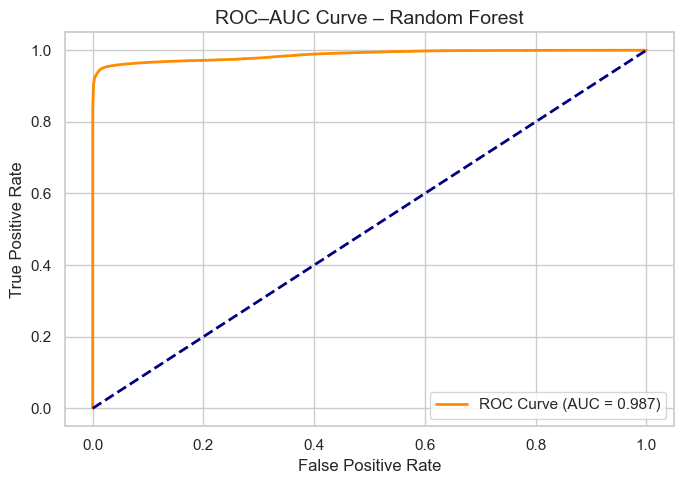

In [95]:
# --------------------------
# 4. ROC–AUC CURVE
# --------------------------
sns.set(style="whitegrid")
plt.figure(figsize=(7,5))
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC Curve (AUC = {auc:.3f})')
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.title('ROC–AUC Curve – Random Forest', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


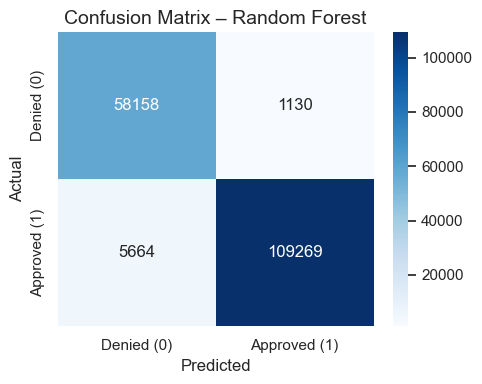

In [96]:
# --------------------------
# 5. CONFUSION MATRIX
# --------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Denied (0)', 'Approved (1)'],
            yticklabels=['Denied (0)', 'Approved (1)'])
plt.title('Confusion Matrix – Random Forest', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [97]:
# --------------------------
# 6. FAIRNESS METRICS (by Race)
# --------------------------
race_attr = selected_df.loc[y_test.index, 'derived_race']

mf = MetricFrame(
    metrics={"accuracy": accuracy_score, "selection_rate": selection_rate},
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=race_attr
)

spd = demographic_parity_difference(y_test, y_pred, sensitive_features=race_attr)
eod = equalized_odds_difference(y_test, y_pred, sensitive_features=race_attr)

# Compute Disparate Impact Ratio (DIR)
group_rates = mf.by_group['selection_rate']
priv = group_rates.idxmax()
unpriv = group_rates.idxmin()
dir_ratio = group_rates[unpriv] / group_rates[priv] if group_rates[priv] > 0 else np.nan

print("\n=== ⚖️ FAIRNESS METRICS (Race) ===")
print(mf.by_group)
print(f"\nStatistical Parity Difference: {spd:.4f}")
print(f"Equal Opportunity Difference:  {eod:.4f}")
print(f"Disparate Impact Ratio ({unpriv} vs {priv}): {dir_ratio:.3f}")


=== ⚖️ FAIRNESS METRICS (Race) ===
                                           accuracy  selection_rate
derived_race                                                       
2 or more minority races                   0.985830        0.550607
American Indian or Alaska Native           0.963208        0.526858
Asian                                      0.972731        0.631264
Black or African American                  0.972571        0.508523
Joint                                      0.970844        0.669821
Native Hawaiian or Other Pacific Islander  0.972900        0.527100
Unknown                                    0.961470        0.590135
White                                      0.958556        0.656361

Statistical Parity Difference: 0.1613
Equal Opportunity Difference:  0.0425
Disparate Impact Ratio (Black or African American vs Joint): 0.759


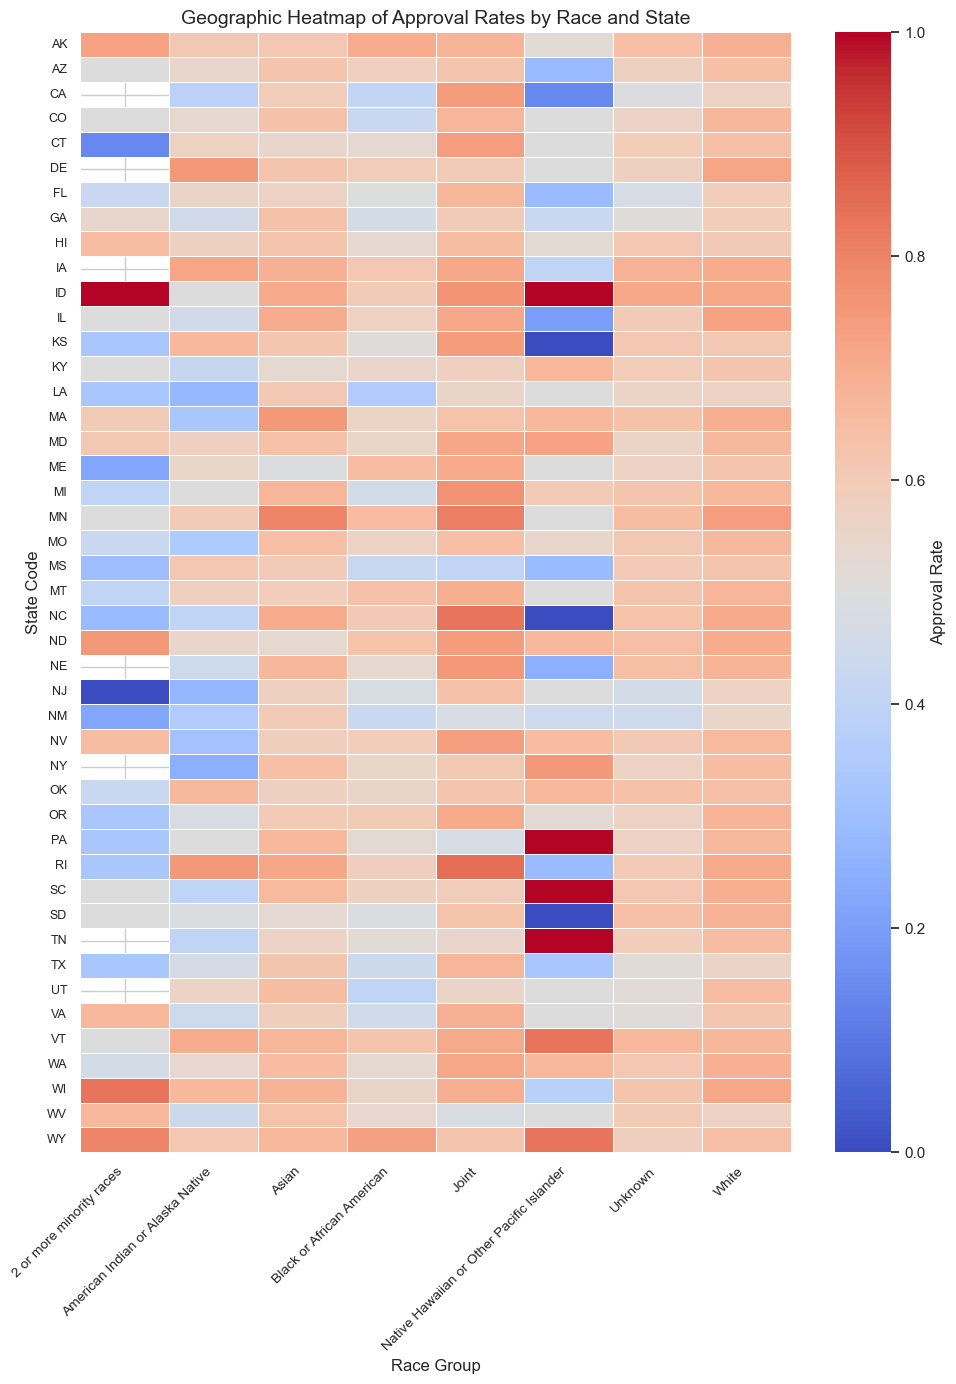

In [98]:
# --------------------------
# 8. GEOGRAPHIC BIAS HEATMAP
# --------------------------
geo_df = selected_df.loc[y_test.index].copy()
geo_df['predicted'] = y_pred

plt.figure(figsize=(10, 14))  # increase height for all states
state_bias = geo_df.groupby(['state_code', 'derived_race'])['predicted'].mean().unstack()
state_bias = state_bias.sort_index()  # optional, keeps alphabetical order

sns.heatmap(
    state_bias,
    cmap='coolwarm',
    linewidths=0.5,
    cbar_kws={'label': 'Approval Rate'}
)

plt.title("Geographic Heatmap of Approval Rates by Race and State", fontsize=14)
plt.xlabel("Race Group", fontsize=12)
plt.ylabel("State Code", fontsize=12)

# Force all state labels to show
plt.yticks(np.arange(len(state_bias.index)) + 0.5, state_bias.index, rotation=0, fontsize=9)
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()
plt.show()


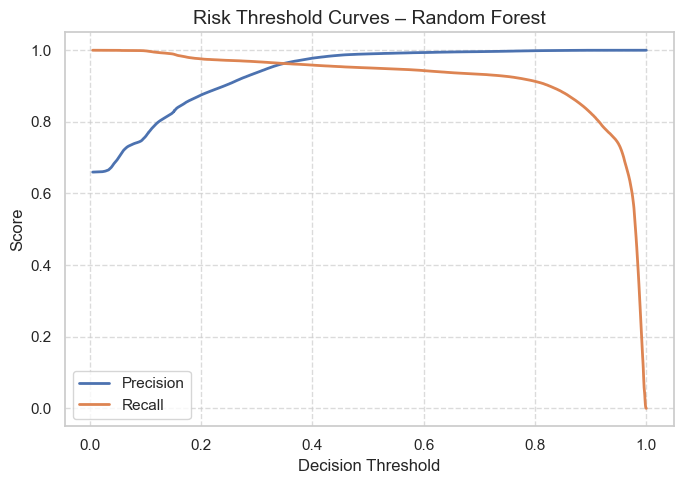

In [99]:
# --------------------------
# 9. RISK THRESHOLD CURVES
# --------------------------


prec, rec, thresh = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(7,5))
plt.plot(thresh, prec[:-1], label='Precision', lw=2)
plt.plot(thresh, rec[:-1], label='Recall', lw=2)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Risk Threshold Curves – Random Forest", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [100]:
# --------------------------
# 10. RUNTIME & RESOURCE USAGE
# --------------------------
sample = X_test.sample(10000, random_state=42)
start = time.time()
rf_model.predict(sample)
elapsed = time.time() - start
print(f"\n⚡ Runtime per 10K applications: {elapsed:.2f} seconds")


⚡ Runtime per 10K applications: 0.20 seconds
